
This notebook consolidates the survival, 
robustness, and external-validation findings.

In [10]:
from pathlib import Path

import pandas as pd

PROJECT_DIR = Path.cwd().parent
TABLES_DIR = PROJECT_DIR / "results" / "tables"

clinical_survival_data = pd.read_csv(
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_clinical_survival_analysis.csv"
)

matched_survival_data = pd.read_csv(
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_matched_clinical_survival_data.csv"
)

validation_results = pd.read_csv(
    TABLES_DIR / "table_09_tcga_external_myeloid_validation.csv"
)

tcga_validation_row = validation_results.loc[
    validation_results["cohort"] == "TCGA-KIRC discovery cohort"
].iloc[0]

external_validation_row = validation_results.loc[
    validation_results["cohort"] == "E-MTAB-1980 external cohort"
].iloc[0]

final_summary = pd.DataFrame(
    [
        {
            "result_type": "Clinical survival cohort",
            "cohort_or_analysis": "TCGA-KIRC clinical cohort",
            "patients": len(clinical_survival_data),
            "deaths": int(clinical_survival_data["event_observed"].sum()),
            "estimate": "Clinical survival-analysis cohort",
            "confidence_interval": "",
            "p_value": "",
        },
        {
            "result_type": "Expression-matched cohort",
            "cohort_or_analysis": "TCGA-KIRC matched cohort",
            "patients": len(matched_survival_data),
            "deaths": int(matched_survival_data["event_observed"].sum()),
            "estimate": "RNA-seq expression available",
            "confidence_interval": "",
            "p_value": "",
        },
        {
            "result_type": "Primary survival association",
            "cohort_or_analysis": tcga_validation_row["cohort"],
            "patients": int(tcga_validation_row["patients"]),
            "deaths": int(tcga_validation_row["deaths"]),
            "estimate": (
                f"HR {tcga_validation_row['hazard_ratio_per_SD']:.2f} "
                "per 1-SD higher myeloid score"
            ),
            "confidence_interval": (
                f"{tcga_validation_row['lower_95_CI']:.2f}"
                f"–{tcga_validation_row['upper_95_CI']:.2f}"
            ),
            "p_value": tcga_validation_row["p_value"],
        },
        {
            "result_type": "External validation",
            "cohort_or_analysis": external_validation_row["cohort"],
            "patients": int(external_validation_row["patients"]),
            "deaths": int(external_validation_row["deaths"]),
            "estimate": (
                f"HR {external_validation_row['hazard_ratio_per_SD']:.2f} "
                "per 1-SD higher myeloid score"
            ),
            "confidence_interval": (
                f"{external_validation_row['lower_95_CI']:.2f}"
                f"–{external_validation_row['upper_95_CI']:.2f}"
            ),
            "p_value": external_validation_row["p_value"],
        },
    ]
)

final_summary_file = (
    TABLES_DIR / "table_15_final_project_summary.csv"
)

final_summary.to_csv(final_summary_file, index=False)

print(f"Final summary table saved as: {final_summary_file.name}")
display(final_summary)

Final summary table saved as: table_15_final_project_summary.csv


,result_type,cohort_or_analysis,patients,deaths,estimate,confidence_interval,p_value
0,Clinical survival cohort,TCGA-KIRC clinical cohort,522,173,Clinical survival-analysis cohort,,
1,Expression-matched cohort,TCGA-KIRC matched cohort,518,171,RNA-seq expression available,,
2,Primary survival association,TCGA-KIRC discovery cohort,518,171,HR 1.35 per 1-SD higher myeloid score,1.18–1.55,0.0001
3,External validation,E-MTAB-1980 external cohort,101,23,HR 1.67 per 1-SD higher myeloid score,1.12–2.49,0.011458


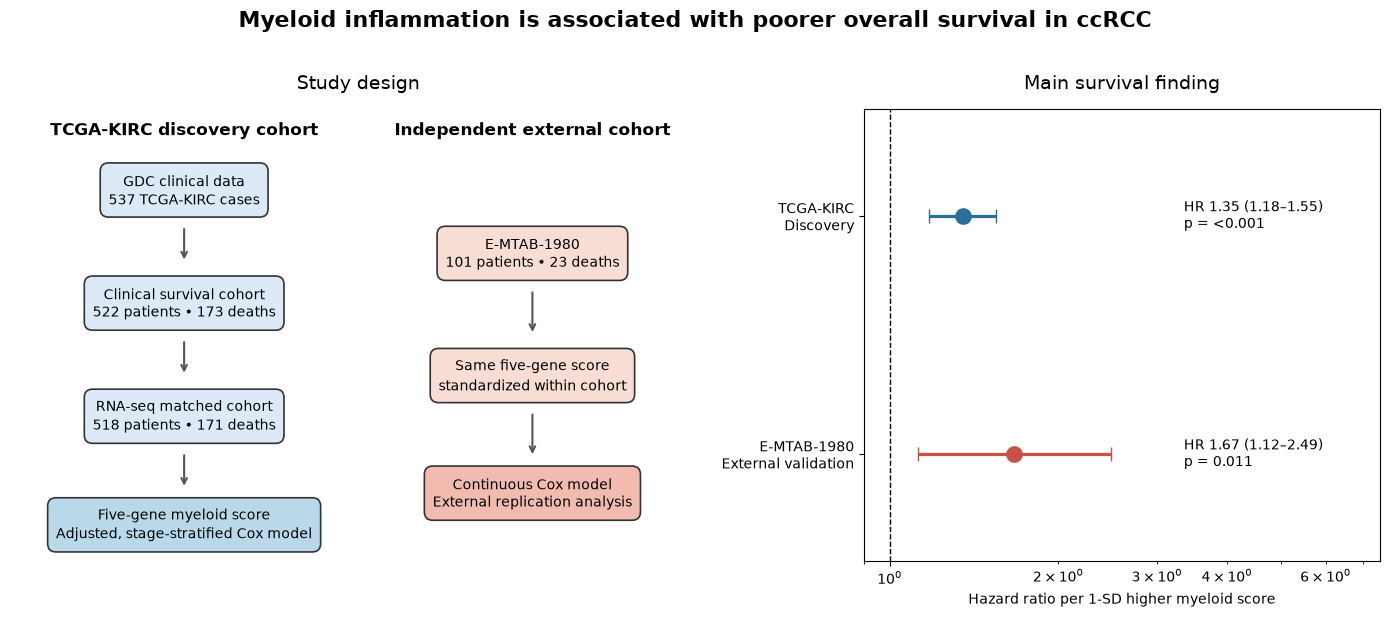

Figure saved as: figure_12_main_result.png


In [12]:
import matplotlib.pyplot as plt
import numpy as np

FIGURES_DIR = PROJECT_DIR / "results" / "figures"

fig, (axis_flow, axis_forest) = plt.subplots(
    ncols=2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.35, 1]},
)

def add_box(axis, x_position, y_position, text, color):
    axis.text(
        x_position,
        y_position,
        text,
        ha="center",
        va="center",
        fontsize=10,
        linespacing=1.35,
        bbox={
            "boxstyle": "round,pad=0.6",
            "facecolor": color,
            "edgecolor": "#333333",
            "linewidth": 1.2,
        },
    )

def add_arrow(axis, x_position, start_y, end_y):
    axis.annotate(
        "",
        xy=(x_position, end_y),
        xytext=(x_position, start_y),
        arrowprops={
            "arrowstyle": "->",
            "color": "#555555",
            "linewidth": 1.5,
        },
    )

axis_flow.set_xlim(0, 1)
axis_flow.set_ylim(0, 1)
axis_flow.axis("off")
axis_flow.set_title("Study design", fontsize=14, pad=14)

axis_flow.text(
    0.25, 0.97, "TCGA-KIRC discovery cohort",
    ha="center", va="top", fontsize=12, fontweight="bold",
)
axis_flow.text(
    0.75, 0.97, "Independent external cohort",
    ha="center", va="top", fontsize=12, fontweight="bold",
)

add_box(
    axis_flow, 0.25, 0.82,
    "GDC clinical data\n537 TCGA-KIRC cases",
    "#DCEAF7",
)
add_arrow(axis_flow, 0.25, 0.74, 0.66)

add_box(
    axis_flow, 0.25, 0.57,
    "Clinical survival cohort\n522 patients • 173 deaths",
    "#DCEAF7",
)
add_arrow(axis_flow, 0.25, 0.49, 0.41)

add_box(
    axis_flow, 0.25, 0.32,
    "RNA-seq matched cohort\n518 patients • 171 deaths",
    "#DCEAF7",
)
add_arrow(axis_flow, 0.25, 0.24, 0.16)

add_box(
    axis_flow, 0.25, 0.08,
    "Five-gene myeloid score\nAdjusted, stage-stratified Cox model",
    "#B9D9EB",
)

add_box(
    axis_flow, 0.75, 0.68,
    "E-MTAB-1980\n101 patients • 23 deaths",
    "#F8DDD5",
)
add_arrow(axis_flow, 0.75, 0.60, 0.50)

add_box(
    axis_flow, 0.75, 0.41,
    "Same five-gene score\nstandardized within cohort",
    "#F8DDD5",
)
add_arrow(axis_flow, 0.75, 0.33, 0.23)

add_box(
    axis_flow, 0.75, 0.15,
    "Continuous Cox model\nExternal replication analysis",
    "#F1BBB0",
)

plot_data = pd.read_csv(
    TABLES_DIR / "table_09_tcga_external_myeloid_validation.csv"
)
y_positions = [1, 0]
colors = ["#2A6F97", "#C75146"]

for y_position, (_, row), color in zip(
    y_positions,
    plot_data.iterrows(),
    colors,
):
    axis_forest.errorbar(
        row["hazard_ratio_per_SD"],
        y_position,
        xerr=[
            [row["hazard_ratio_per_SD"] - row["lower_95_CI"]],
            [row["upper_95_CI"] - row["hazard_ratio_per_SD"]],
        ],
        fmt="o",
        color=color,
        markersize=11,
        capsize=5,
        linewidth=2.3,
    )

    p_value_text = (
        "<0.001" if row["p_value"] < 0.001
        else f"{row['p_value']:.3f}"
    )

    axis_forest.text(
        3.35,
        y_position,
        (
            f"HR {row['hazard_ratio_per_SD']:.2f} "
            f"({row['lower_95_CI']:.2f}–{row['upper_95_CI']:.2f})\n"
            f"p = {p_value_text}"
        ),
        va="center",
        fontsize=10,
    )

axis_forest.axvline(1, color="black", linestyle="--", linewidth=1)
axis_forest.set_xscale("log")
axis_forest.set_xlim(0.9, 7.5)
axis_forest.set_ylim(-0.45, 1.45)
axis_forest.set_yticks(y_positions)
axis_forest.set_yticklabels(
    [
        "TCGA-KIRC\nDiscovery",
        "E-MTAB-1980\nExternal validation",
    ]
)
axis_forest.set_xlabel("Hazard ratio per 1-SD higher myeloid score")
axis_forest.set_title("Main survival finding", fontsize=14, pad=14)
axis_forest.grid(axis="x", alpha=0.25)
axis_forest.grid(axis="y", visible=False)

fig.suptitle(
    "Myeloid inflammation is associated with poorer overall survival in ccRCC",
    fontsize=16,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

overview_figure_file = (
    FIGURES_DIR / "figure_12_main_result.png"
)

fig.savefig(overview_figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {overview_figure_file.name}")

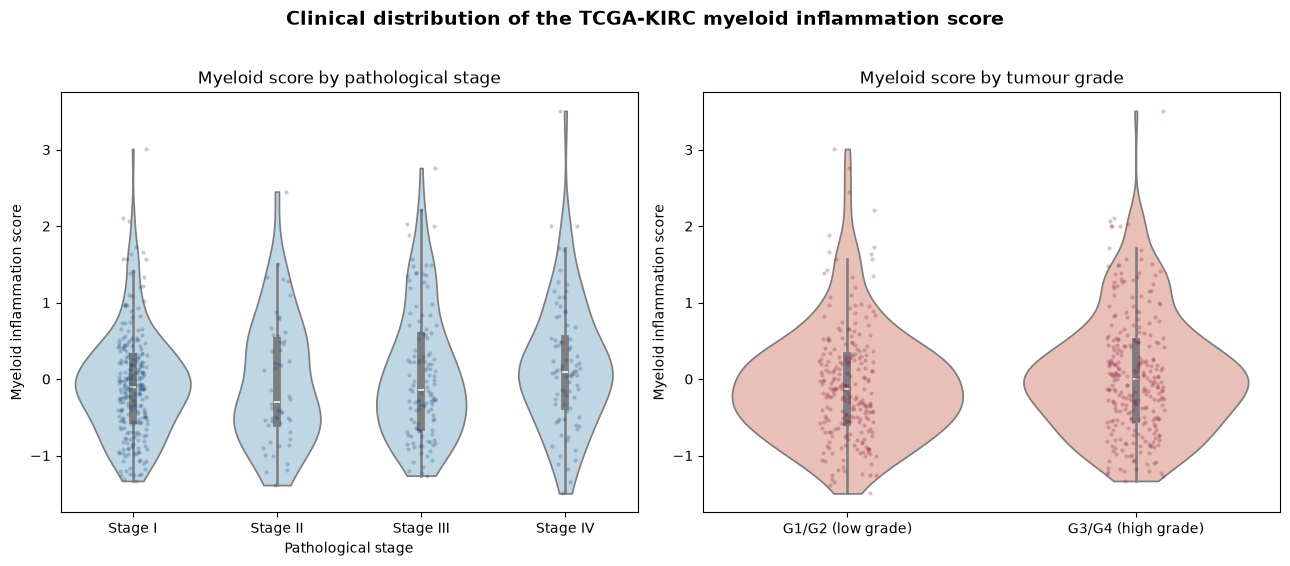

Figure saved as: figure_13_myeloid_score_clinical_context.png


In [11]:
# Visualizing myeloid inflammation across tumour stage and grade
import seaborn as sns
analysis_data = pd.read_csv(
    PROJECT_DIR
    / "data"
    / "processed"
    / "tcga_kirc_clinical_immune_signature_analysis_data.csv"
)

analysis_data["grade_group"] = np.where(
    analysis_data["tumor_grade"].isin(["G3", "G4"]),
    "G3/G4 (high grade)",
    "G1/G2 (low grade)",
)

stage_order = ["Stage I", "Stage II", "Stage III", "Stage IV"]
grade_order = ["G1/G2 (low grade)", "G3/G4 (high grade)"]

fig, axes = plt.subplots(ncols=2, figsize=(13, 5.5))

sns.violinplot(
    data=analysis_data,
    x="tumor_stage",
    y="myeloid_inflammation_score",
    order=stage_order,
    color="#B9D9EB",
    inner="box",
    cut=0,
    ax=axes[0],
)

sns.stripplot(
    data=analysis_data,
    x="tumor_stage",
    y="myeloid_inflammation_score",
    order=stage_order,
    color="#1F4E79",
    alpha=0.28,
    size=3,
    ax=axes[0],
)

axes[0].set_title("Myeloid score by pathological stage")
axes[0].set_xlabel("Pathological stage")
axes[0].set_ylabel("Myeloid inflammation score")

sns.violinplot(
    data=analysis_data,
    x="grade_group",
    y="myeloid_inflammation_score",
    order=grade_order,
    color="#F1BBB0",
    inner="box",
    cut=0,
    ax=axes[1],
)

sns.stripplot(
    data=analysis_data,
    x="grade_group",
    y="myeloid_inflammation_score",
    order=grade_order,
    color="#8B1E3F",
    alpha=0.28,
    size=3,
    ax=axes[1],
)

axes[1].set_title("Myeloid score by tumour grade")
axes[1].set_xlabel("")
axes[1].set_ylabel("Myeloid inflammation score")

fig.suptitle(
    "Clinical distribution of the TCGA-KIRC myeloid inflammation score",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

clinical_context_figure_file = (
    FIGURES_DIR / "figure_13_myeloid_score_clinical_context.png"
)

fig.savefig(clinical_context_figure_file, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved as: {clinical_context_figure_file.name}")

## Key findings

The final TCGA-KIRC expression-matched cohort included 518 patients and 171 deaths. A five-gene myeloid inflammation score (CXCL1, CXCL2, CXCL3, IL6, and PTGS2) was associated with poorer overall survival after adjustment for age, sex, tumour grade, and pathological stage stratification (HR 1.35 per standard-deviation increase; 95% CI 1.18–1.55; p < 0.001).

The association replicated in the independent E-MTAB-1980 ccRCC cohort (101 patients; 23 deaths; HR 1.67; 95% CI 1.12–2.49; p = 0.011). Leave-one-gene-out analyses showed that the result was not dependent on a single gene.

These findings are observational associations. Please note that they do not establish causality